# 实验报告 02：NumPy、SciPy、Matplotlib 与 pandas 数据处理

- **姓名**：莫家豪
- **学号**：20244081121
- **环境**：独立 conda 虚拟环境 `py312`（Python 3.12），已安装 Jupyter Notebook、NumPy、SciPy、Matplotlib 和 pandas

> 请先运行第一个代码框记录身份信息，再按顺序从上到下运行各代码框。涉及随机抽样的部分统一使用固定种子 `SEED = 20244081121`，结果可复现；所有图表均在 Notebook 内嵌显示，不保存为文件。

## 0. 第一个代码框：身份与环境记录

填写学号，打印当前 conda 环境、机器指纹（绑定当前电脑）、唯一 RUN_ID 与依赖库版本。

In [1]:
import os
import uuid
import hashlib
import platform

import numpy as np
import scipy
import matplotlib
import pandas as pd

# ===== 修改为自己的学号 =====
STUDENT_ID = 20244081121

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹]   {MACHINE_FP}")
print(f"[RUN_ID]     {RUN_ID}")
print(f"[numpy {np.__version__}] [scipy {scipy.__version__}] "
      f"[matplotlib {matplotlib.__version__}] [pandas {pd.__version__}]")

[Conda 环境] py312
[学号]       20244081121
[机器指纹]   ba436aa86f711356
[RUN_ID]     20244081121-ba436aa86f711356
[numpy 2.5.4] [scipy 1.18.1] [matplotlib 3.11.2] [pandas 3.0.6]


In [2]:
# bonjour

# ===== 全局配置：固定随机种子 + 图表中文字体 =====
SEED = 20244081121                 # 所有涉及随机抽样的实验统一使用该种子
np.random.seed(SEED % 2**32)       # 种子须在 0 ~ 2**32-1 内, 故取学号模 2**32

import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]  # 图表正常显示中文
plt.rcParams["axes.unicode_minus"] = False                       # 负号正常显示

print("全局随机种子 SEED =", SEED, "；中文字体配置完成")

全局随机种子 SEED = 20244081121 ；中文字体配置完成


# 实验 1：NumPy 数组、数据类型与索引

### 1.1 三种数据类型的 `ndarray`

分别创建整数、浮点数、布尔数组，输出 `dtype`、`shape`、`ndim`。

In [3]:
arr_int   = np.array([1, 2, 3, 4])           # 整数数组
arr_float = np.array([1.5, 2.5, 3.5])        # 浮点数数组
arr_bool  = np.array([True, False, True])    # 布尔数组

for name, arr in [("arr_int", arr_int), ("arr_float", arr_float), ("arr_bool", arr_bool)]:
    print(f"{name:<10} dtype = {arr.dtype!s:<8} shape = {arr.shape!s:<8} ndim = {arr.ndim}")

arr_int    dtype = int64    shape = (4,)     ndim = 1
arr_float  dtype = float64  shape = (3,)     ndim = 1
arr_bool   dtype = bool     shape = (3,)     ndim = 1


**NumPy 数组与 Python 列表的差别**：

- **类型固定**：数组的 `dtype` 在创建时确定，所有元素必须是同一类型（如 `int64`、`float64`、`bool`）；列表元素类型可以任意混杂；
- **连续存储**：同类型元素在内存中连续存放，列表存的是对象的指针；因此数组更省内存、对缓存更友好；
- **向量化运算**：数组支持整体运算（如 `arr * 2`、`arr > 3`），列表做同样的事必须写循环或推导式；
- **大小固定**：`ndarray` 创建后不能像列表那样随意增删元素，改变形状只是生成新的"视图"。

### 1.2 `np.arange(12)` 变形为 `(3, 4)` 与 `(2, 3, 2)`

In [4]:
a12 = np.arange(12)

a_3x4   = a12.reshape(3, 4)      # 3 行 4 列
a_2x3x2 = a12.reshape(2, 3, 2)   # 2×3×2 的三维数组

print("一维数组 a12 =", a12, "\n")
print("形状 (3, 4) 的数组:\n", a_3x4, "\n")
print("形状 (2, 3, 2) 的数组:\n", a_2x3x2)

一维数组 a12 = [ 0  1  2  3  4  5  6  7  8  9 10 11] 

形状 (3, 4) 的数组:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]] 

形状 (2, 3, 2) 的数组:
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


**改变形状的条件**：变形前后**元素总数必须相等**——`reshape` 只改变元素的"摆放方式"，不增删元素。`(3, 4)` 与 `(2, 3, 2)` 各维乘积都是 12，与 `np.arange(12)` 的长度一致；若尝试 `a12.reshape(5, 3)`（乘积 15 ≠ 12）会抛出 `ValueError: cannot reshape array of size 12 into shape (5,3)`。

### 1.3 对 `(3, 4)` 数组的三种索引

取第 2 行、取第 1 至第 3 列、取大于 6 的元素，并输出结果及形状。

In [5]:
a = a_3x4        # 使用 1.2 得到的 (3, 4) 数组

row2     = a[1]        # 第 2 行(索引从 0 开始, 故为 1)
col1to3  = a[:, 0:3]   # 第 1 至第 3 列, 即索引 0、1、2 的列
greater6 = a[a > 6]    # 大于 6 的所有元素(布尔索引, 返回一维数组)

print("原数组:\n", a, "\n")
print("第 2 行        =", row2, "     形状 =", row2.shape)
print("第 1 至第 3 列:\n", col1to3, " 形状 =", col1to3.shape)
print("大于 6 的元素  =", greater6, "  形状 =", greater6.shape)

原数组:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]] 

第 2 行        = [4 5 6 7]      形状 = (4,)
第 1 至第 3 列:
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]]  形状 = (3, 3)
大于 6 的元素  = [ 7  8  9 10 11]   形状 = (5,)


行索引 `a[1]` 得到长度 4 的一维数组；列切片 `a[:, 0:3]` 得到 `(3, 3)` 的二维数组；布尔索引 `a[a > 6]` 自动把满足条件的元素**压平**成一维数组 `(6,)`。

### 1.4 布尔条件筛选：`|`、`&` 与 `np.logical_or()`、`np.logical_and()`

用 `np.arange(10)` 分别选出"小于 2 或大于 7"与"大于 3 且小于 7"的元素。注意每个条件必须加括号再组合。

In [6]:
b = np.arange(10)

or_mask  = (b < 2) | (b > 7)               # 小于 2 或大于 7
and_mask = np.logical_and(b > 3, b < 7)    # 大于 3 且小于 7

print("数组 b              =", b)
print("(b < 2) | (b > 7)   =", b[or_mask], "  掩码 =", or_mask.astype(int))
print("logical_and(>3, <7) =", b[and_mask], "      掩码 =", and_mask.astype(int))

# | 与 np.logical_or、& 与 np.logical_and 结果完全等价
assert np.array_equal(b[(b < 2) | (b > 7)], b[np.logical_or(b < 2, b > 7)])
assert np.array_equal(b[(b > 3) & (b < 7)], b[np.logical_and(b > 3, b < 7)])
print("\n两种写法的结果完全一致")

数组 b              = [0 1 2 3 4 5 6 7 8 9]
(b < 2) | (b > 7)   = [0 1 8 9]   掩码 = [1 1 0 0 0 0 0 0 1 1]
logical_and(>3, <7) = [4 5 6]       掩码 = [0 0 0 0 1 1 1 0 0 0]

两种写法的结果完全一致


### 1.5 逐元素乘法 vs 矩阵乘法

构造两个 `(2, 2)` 数组，对比 `*`、`np.multiply()` 与 `@`、`np.matmul()`。

In [7]:
m1 = np.array([[1, 2], [3, 4]])
m2 = np.array([[5, 6], [7, 8]])

print("m1 =\n", m1, "\nm2 =\n", m2, "\n")
print("逐元素: m1 * m2 =\n", m1 * m2)
print("逐元素: np.multiply(m1, m2) =\n", np.multiply(m1, m2), "\n")
print("矩阵:   m1 @ m2 =\n", m1 @ m2)
print("矩阵:   np.matmul(m1, m2) =\n", np.matmul(m1, m2))

m1 =
 [[1 2]
 [3 4]] 
m2 =
 [[5 6]
 [7 8]] 

逐元素: m1 * m2 =
 [[ 5 12]
 [21 32]]
逐元素: np.multiply(m1, m2) =
 [[ 5 12]
 [21 32]] 

矩阵:   m1 @ m2 =
 [[19 22]
 [43 50]]
矩阵:   np.matmul(m1, m2) =
 [[19 22]
 [43 50]]


**区别**：`*` 与 `np.multiply()` 是**逐元素乘法**——对应位置各自相乘，如左上角 `1×5 = 5`；`@` 与 `np.matmul()` 是**矩阵乘法**——行乘列再求和，如左上角 `1×5 + 2×7 = 19`。两对运算符内部各自等价，但两组之间一般结果完全不同。

# 实验 2：随机抽样、统计与缺失值

本实验所有随机操作前都用 `np.random.seed(SEED % 2**32)` 固定种子，保证每次运行结果一致。

### 2.1 模拟成绩：生成 + `np.clip` 限幅 + 统计

In [8]:
np.random.seed(SEED % 2**32)                                     # 固定种子(学号模 2**32)
scores = np.random.normal(loc=70, scale=10, size=1000)   # 均值 70, 标准差 10
scores = np.clip(scores, 0, 100)                         # 限制在 0 ~ 100

print(f"样本数 = {scores.size}")
print(f"最小值 = {scores.min():.2f}")
print(f"最大值 = {scores.max():.2f}")
print(f"均值   = {scores.mean():.2f}")
print(f"标准差 = {scores.std():.2f}")
print(f"极差   = {scores.max() - scores.min():.2f}")

样本数 = 1000
最小值 = 41.62
最大值 = 100.00
均值   = 70.74
标准差 = 9.91
极差   = 58.38


1,000 个样本的均值约 70、标准差略小于 10（因 `clip` 截掉了两侧尾部，方差被压缩），最小值/最大值分别被限制在 0 和 100 以内，极差 = 最大值 − 最小值。

### 2.2 均匀抽样 vs 按整数大小成比例加权抽样

从 `np.arange(1, 11)` 中不放回地抽取 5 个整数，比较两种写法。

In [9]:
pool = np.arange(1, 11)                    # 候选整数 1 ~ 10

np.random.seed(SEED % 2**32)
uniform_draw  = np.random.choice(pool, size=5, replace=False)      # 均匀抽样
weighted_draw = np.random.choice(pool, size=5, replace=False,
                                 p=pool / pool.sum())              # 按数值大小加权

print("候选池               =", pool)
print("均匀抽样(不放回)     =", np.sort(uniform_draw))
print("加权抽样(不放回)     =", np.sort(weighted_draw))
print("加权概率 p(保留3位)  =", np.round(pool / pool.sum(), 3))

候选池               = [ 1  2  3  4  5  6  7  8  9 10]
均匀抽样(不放回)     = [1 2 4 5 7]
加权抽样(不放回)     = [ 4  7  8  9 10]
加权概率 p(保留3位)  = [0.018 0.036 0.055 0.073 0.091 0.109 0.127 0.145 0.164 0.182]


**两种写法的比较**：唯一区别是 `choice` 是否传入概率向量 `p`。
- 均匀抽样：不传 `p`，每个数被抽到的概率相同（1/10）；
- 加权抽样：`p = pool / pool.sum()`，数值越大被抽中的概率越高（如 10 的概率是 1 的 10 倍），因此加权样本整体明显偏大；
- `replace=False` 表示不放回，抽过的数不会再出现。

### 2.3 `permutation`（保留原数组）vs `shuffle`（原地打乱）

In [10]:
src1 = np.arange(1, 9)
src2 = np.arange(1, 9)

# 方式一: permutation 返回打乱后的新数组, 原数组保持不变
print("permutation:")
print("  操作前 src1 =", src1)
permuted = np.random.permutation(src1)
print("  操作后 src1 =", src1, "<- 原数组不变")
print("  返回的新数组 =", permuted)

# 方式二: shuffle 直接在原数组上原地打乱, 无返回值
print("shuffle:")
print("  操作前 src2 =", src2)
np.random.shuffle(src2)
print("  操作后 src2 =", src2, "<- 原数组被原地修改")

permutation:
  操作前 src1 = [1 2 3 4 5 6 7 8]
  操作后 src1 = [1 2 3 4 5 6 7 8] <- 原数组不变
  返回的新数组 = [5 1 7 6 3 2 4 8]
shuffle:
  操作前 src2 = [1 2 3 4 5 6 7 8]
  操作后 src2 = [7 2 3 6 8 1 5 4] <- 原数组被原地修改


**区别**：`np.random.permutation(arr)` 返回一个打乱后的**新数组**，`arr` 本身不动；`np.random.shuffle(arr)` **原地**打乱 `arr`，返回值是 `None`。需要保留原始顺序时用 `permutation`（或先 `copy()` 再 `shuffle`）。

### 2.4 缺失值 `np.nan` 对统计函数的影响

把第 10、20、30 个值（索引 9、19、29）设为 `np.nan`，比较普通均值与忽略缺失值后的均值。

In [11]:
scores_nan = scores.copy()                # 复制一份, 不污染 2.1 的干净数据
scores_nan[[9, 19, 29]] = np.nan          # 第 10、20、30 个值设为 nan

print("普通均值 mean    =", scores_nan.mean())          # nan 会“传染”
print("忽略缺失 nanmean =", np.nanmean(scores_nan))
print(f"缺失值个数       = {np.isnan(scores_nan).sum()}")

普通均值 mean    = nan
忽略缺失 nanmean = 70.7280464747196
缺失值个数       = 3


**说明**：`nan` 与任何数做算术运算的结果仍是 `nan`，因此 `mean`、`sum`、`max` 等**普通统计函数只要输入含 nan，结果就是 nan**（"传染性"）。要得到有效统计值，须改用 `np.nanmean` 等"忽略 nan"版本（结果约 70.73），或先用 `np.isnan()` 过滤再统计。

### 2.5 整理成内存中的表格变量（供后面实验直接使用）

用 pandas 把含缺失值的成绩与序号（从 1 开始）整理成 `DataFrame`，只保留在内存中，**不写入磁盘**。

In [12]:
score_table = pd.DataFrame({
    "序号": np.arange(1, scores_nan.size + 1),
    "成绩": scores_nan,
})

print("score_table(内存中的 DataFrame, 不写盘) 前 5 行:")
print(score_table.head())
print("\n含缺失值的 3 行:")
print(score_table[score_table["成绩"].isna()])

score_table(内存中的 DataFrame, 不写盘) 前 5 行:
   序号         成绩
0   1  54.045885
1   2  60.341272
2   3  67.907692
3   4  70.839274
4   5  57.653094

含缺失值的 3 行:
    序号  成绩
9   10 NaN
19  20 NaN
29  30 NaN


`score_table` 共 1,000 行、2 列，其中序号 10、20、30 的成绩为 `NaN`。后续实验直接读取内存中的这个变量，全程未产生任何磁盘文件。

# 实验 3：SciPy 数值计算与 Matplotlib 可视化

### 3.1 `scipy.linalg.solve()` 解线性方程组

解方程组 $3x + y = 9$、$x + 2y = 8$，再用 NumPy 把解代回原方程验证。

In [13]:
from scipy import linalg

A_mat = np.array([[3.0, 1.0], [1.0, 2.0]])   # 系数矩阵
b_vec = np.array([9.0, 8.0])                 # 右端向量

xy = linalg.solve(A_mat, b_vec)
print(f"解得 x = {xy[0]}, y = {xy[1]}")

# NumPy 代入验证: A @ xy 应等于 b
print("代入验证 A @ xy =", A_mat @ xy, " 原方程右端 =", b_vec)
print("残差 A @ xy - b =", A_mat @ xy - b_vec, "(接近 0 说明解正确)")

解得 x = 2.000000000000001, y = 2.9999999999999996
代入验证 A @ xy = [9. 8.]  原方程右端 = [9. 8.]
残差 A @ xy - b = [1.77635684e-15 0.00000000e+00] (接近 0 说明解正确)


解得 `x = 2.0, y = 3.0`（手算：由两式消元可得 x=2, y=3）。代回后残差仅 1e-15 量级（机器精度），验证通过。

### 3.2 `scipy.optimize.root()` 求 x² − 2 = 0 的正根和负根

分别用正、负初始猜测值求根，打印是否成功、根的数值，并检查函数值是否接近 0。

In [14]:
from scipy import optimize

def f(x):
    return x ** 2 - 2


root_pos = optimize.root(f, x0=1.5)      # 正根: 初始猜测 1.5
root_neg = optimize.root(f, x0=-1.5)     # 负根: 初始猜测 -1.5

print(f"正根: 求根成功 = {root_pos.success}, 根 ≈ {root_pos.x[0]:.6f}, "
      f"f(根) = {f(root_pos.x[0]):.2e}, 参考值 +√2 = {np.sqrt(2):.6f}")
print(f"负根: 求根成功 = {root_neg.success}, 根 ≈ {root_neg.x[0]:.6f}, "
      f"f(根) = {f(root_neg.x[0]):.2e}, 参考值 -√2 = {-np.sqrt(2):.6f}")

正根: 求根成功 = True, 根 ≈ 1.414214, f(根) = 4.44e-16, 参考值 +√2 = 1.414214
负根: 求根成功 = True, 根 ≈ -1.414214, f(根) = 4.44e-16, 参考值 -√2 = -1.414214


两个初值分别收敛到 ±√2 ≈ ±1.414214：`success = True` 表示迭代收敛，残差 `f(根)` 约 4.4e-16、非常接近 0，求根结果可信。初始猜测值决定收敛到正根还是负根。

### 3.3 `scipy.optimize.minimize()` 求 f(x) = x² + x + 2 的最小值

In [15]:
def g(x):
    return x ** 2 + x + 2


res_min = optimize.minimize(g, x0=0)
print(f"数值解: 极小点 x* = {res_min.x[0]:.6f}, 极小值 g(x*) = {res_min.fun:.6f}")
print(f"解析解: g'(x) = 2x + 1 = 0  =>  x* = -0.5, g(-0.5) = {g(-0.5)}")
print(f"极小点偏差 |数值 - 解析| = {abs(res_min.x[0] - (-0.5)):.2e}")

数值解: 极小点 x* = -0.500000, 极小值 g(x*) = 1.750000
解析解: g'(x) = 2x + 1 = 0  =>  x* = -0.5, g(-0.5) = 1.75
极小点偏差 |数值 - 解析| = 6.43e-09


数值解 `x* ≈ -0.5`、`g(x*) ≈ 1.75`，与解析结果完全吻合：由 `g'(x) = 2x + 1 = 0` 得 `x* = -1/2`，`g(-1/2) = 1/4 − 1/2 + 2 = 1.75`。

### 3.4 独立样本 t 检验

生成两组各 100 个观测值：N(0, 1) 与 N(1, 1)，固定随机种子，用 `scipy.stats.ttest_ind()` 检验两组均值是否有显著差异。

In [16]:
from scipy import stats

np.random.seed(SEED % 2**32)                                   # 固定种子(学号模 2**32)
sample1 = np.random.normal(loc=0, scale=1, size=100)   # 第一组: N(0, 1)
sample2 = np.random.normal(loc=1, scale=1, size=100)   # 第二组: N(1, 1)

t_stat, p_value = stats.ttest_ind(sample1, sample2)
print(f"样本1 均值 = {sample1.mean():.3f}, 样本2 均值 = {sample2.mean():.3f}")
print(f"t 统计量 = {t_stat:.4f}")
print(f"p 值     = {p_value:.6e}")
if p_value < 0.05:
    print("判断: p < 0.05, 在 0.05 显著性水平下拒绝原假设, 两组均值差异显著")
else:
    print("判断: p >= 0.05, 在 0.05 显著性水平下不能拒绝原假设, 两组均值差异不显著")

样本1 均值 = 0.070, 样本2 均值 = 1.051
t 统计量 = -7.1526
p 值     = 1.611895e-11
判断: p < 0.05, 在 0.05 显著性水平下拒绝原假设, 两组均值差异显著


t 检验的原假设是"两组总体均值相同"。样本 1 均值约 0、样本 2 均值约 1，t 统计量约 −7（负号表示第一组更小），p 值远小于 0.05，因此在 0.05 显著性水平下**拒绝原假设**：两组均值差异显著。

### 3.5 Matplotlib 可视化（直方图、箱线图、折线图）

图表均有标题与坐标轴标签，折线图含图例；全部内嵌显示，不保存为文件。

有效成绩个数 = 997


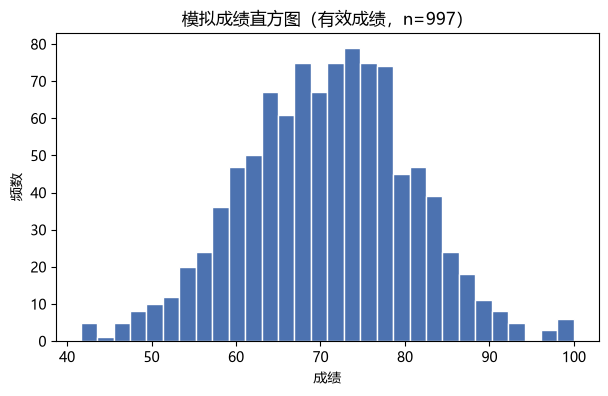

In [17]:
valid_scores = scores_nan[~np.isnan(scores_nan)]   # 实验 2 的有效成绩(去除 nan)
print(f"有效成绩个数 = {valid_scores.size}")

fig1, ax1 = plt.subplots(figsize=(7, 4))
ax1.hist(valid_scores, bins=30, color="#4C72B0", edgecolor="white")
ax1.set_title("模拟成绩直方图（有效成绩，n=997）")
ax1.set_xlabel("成绩")
ax1.set_ylabel("频数")
plt.show()

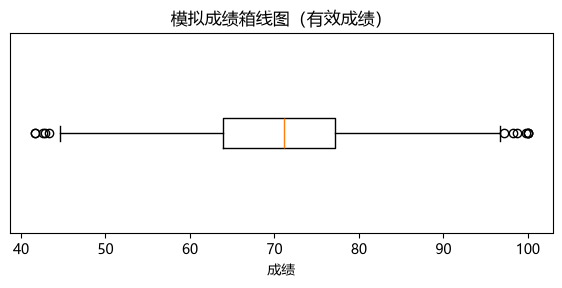

In [18]:
fig2, ax2 = plt.subplots(figsize=(7, 2.6))
ax2.boxplot(valid_scores, orientation="horizontal")
ax2.set_title("模拟成绩箱线图（有效成绩）")
ax2.set_xlabel("成绩")
ax2.set_yticks([])
plt.show()

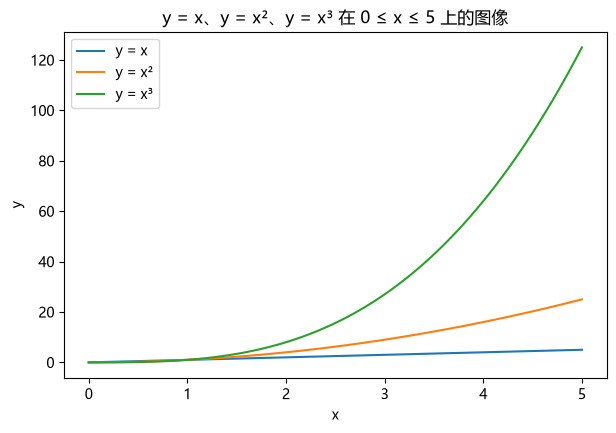

In [19]:
x_line = np.linspace(0, 5, 100)

fig3, ax3 = plt.subplots(figsize=(7, 4.5))
ax3.plot(x_line, x_line,      label="y = x")
ax3.plot(x_line, x_line**2,   label="y = x²")
ax3.plot(x_line, x_line**3,   label="y = x³")
ax3.set_title("y = x、y = x²、y = x³ 在 0 ≤ x ≤ 5 上的图像")
ax3.set_xlabel("x")
ax3.set_ylabel("y")
ax3.legend()
plt.show()

**图形解读**：
- 直方图近似正态分布，中心在 70 附近，与"均值 70、标准差 10"的设定一致；
- 箱线图中位数约 70，箱体（四分位距）约 63～77，个别高分点靠近 100（`clip` 截断所致）；
- 折线图中三条曲线在原点附近接近，随着 x 增大，三次函数的增长远快于二次与一次函数。

# 实验 4：pandas Series、DataFrame 与内存中的 CSV 读写

### 4.1 创建 DataFrame，计算 Total 与 Average

用题目给定的模拟数据创建 DataFrame（行索引为姓名），计算三科总分 `Total` 与平均分 `Average`，输出行索引、列名、前 3 行和基本统计信息。

In [20]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

subjects = ["Math", "English", "Python"]
df = pd.DataFrame(records).set_index("Name")    # 行索引设为姓名
df["Total"]   = df[subjects].sum(axis=1)        # 三科总分
df["Average"] = df[subjects].mean(axis=1)       # 三科平均分

print("行索引:", df.index.tolist())
print("列名  :", df.columns.tolist())
print("\n前 3 行:")
print(df.head(3))
print("\n基本统计信息:")
print(df[subjects + ["Total", "Average"]].describe().round(2))

行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名  : ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行:
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息:
        Math  English  Python   Total  Average
count   6.00     6.00    6.00    6.00     6.00
mean   79.83    80.83   83.67  244.33    81.44
std     9.91     9.66    8.55   25.78     8.59
min    65.00    68.00   70.00  208.00    69.33
25%    73.75    74.00   80.50  225.75    75.25
50%    81.50    81.00   84.00  250.00    83.33
75%    87.00    88.75   88.25  263.00    87.67
max    91.00    92.00   95.00  273.00    91.00


6 名学生、7 列（姓名作行索引 + Group + 三科成绩 + Total + Average）。`describe()` 给出每列的计数、均值、标准差与五数概括，例如 Average 的均值约 81.44。

### 4.2 `loc` 与 `iloc` 读取 Carol，筛选平均分不低于 80 的学生

In [21]:
print("df.loc['Carol']  (按行索引标签):")
print(df.loc["Carol"])
print("\ndf.iloc[2]  (按整数位置, Carol 是第 3 行):")
print(df.iloc[2])

print("\n平均分不低于 80 的学生:")
print(df[df["Average"] >= 80][["Group", "Average"]])

df.loc['Carol']  (按行索引标签):
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

df.iloc[2]  (按整数位置, Carol 是第 3 行):
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分不低于 80 的学生:
      Group    Average
Name                  
Alice     A  91.000000
Carol     B  88.333333
Eva       A  85.666667
Frank     B  81.000000


`loc` 按**标签**（`"Carol"`）取行，`iloc` 按**整数位置**（Carol 排第 3，位置 2）取行，两者得到同一条记录。按 `Average >= 80` 筛出 Alice、Carol、Eva、Frank 四人。

### 4.3 `mean(axis=0)` 列均值 与 `mean(axis=1)` 行均值

In [22]:
print("axis=0 沿行方向压缩 -> 三科成绩的列均值:")
print(df[subjects].mean(axis=0).round(2))
print("\naxis=1 沿列方向压缩 -> 每名学生的行均值:")
print(df[subjects].mean(axis=1).round(2))

axis=0 沿行方向压缩 -> 三科成绩的列均值:
Math       79.83
English    80.83
Python     83.67
dtype: float64

axis=1 沿列方向压缩 -> 每名学生的行均值:
Name
Alice    91.00
Bob      73.33
Carol    88.33
David    69.33
Eva      85.67
Frank    81.00
dtype: float64


`axis=0` 表示沿行方向聚合，结果保留列（每科的均值）；`axis=1` 沿列方向聚合，结果保留行（每名学生的平均分），与 4.1 中的 `Average` 列一致。

### 4.4 `apply()`、`agg()` 与 `rank()`

`apply()` 算每名学生的三科最高分；`agg()` 一次得到每科的最小值、均值和最大值；`rank()` 按 Total 排名。

In [23]:
print("apply: 每名学生三科最高分:")
print(df[subjects].apply(max, axis=1))

print("\nagg: 每科的最小值 / 均值 / 最大值:")
print(df[subjects].agg(["min", "mean", "max"]).round(2))

print("\nrank: 按 Total 从高到低排名(1 为最高):")
print(df["Total"].rank(ascending=False, method="min").astype(int))

apply: 每名学生三科最高分:
Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
dtype: int64

agg: 每科的最小值 / 均值 / 最大值:
       Math  English  Python
min   65.00    68.00   70.00
mean  79.83    80.83   83.67
max   91.00    92.00   95.00

rank: 按 Total 从高到低排名(1 为最高):
Name
Alice    1
Bob      5
Carol    2
David    6
Eva      3
Frank    4
Name: Total, dtype: int64


`apply(max, axis=1)` 对每行调用 `max`；`agg(["min", "mean", "max"])` 把三个聚合函数一次应用到每一列；`rank(ascending=False)` 给出 Alice(273) 第 1、Carol(265) 第 2、Eva(257) 第 3、Frank(243) 第 4、Bob(220) 第 5、David(208) 第 6。

### 4.5 `groupby` 分组统计 与 `transform('mean')` 广播组均值

In [24]:
grouped = df.groupby("Group")

print("每组人数:")
print(grouped.size())
print("\n每组三科平均分:")
print(grouped[subjects].mean().round(2))

df["Group_Py_Mean"] = grouped["Python"].transform("mean")   # 每行加所在组的 Python 均分
print("\n为每行增加所在组的 Python 平均分:")
print(df[["Group", "Python", "Group_Py_Mean"]])

每组人数:
Group
A    3
B    3
dtype: int64

每组三科平均分:
        Math  English  Python
Group                        
A      79.67    83.33   87.00
B      80.00    78.33   80.33

为每行增加所在组的 Python 平均分:
      Group  Python  Group_Py_Mean
Name                              
Alice     A      95      87.000000
Bob       A      80      87.000000
Carol     B      89      80.333333
David     B      70      80.333333
Eva       A      86      87.000000
Frank     B      82      80.333333


`groupby` + `mean` 把数据压缩成每组一行（A、B 各一行）；`transform('mean')` 则返回**与原 DataFrame 等长**的结果，把每个学生所在组的 Python 均分"广播"回该行——A 组 87.0，B 组 80.33。这是 `agg`（压缩）与 `transform`（广播）的核心区别。

### 4.6 `filter()` 保留 Python 平均分不低于 80 的组

In [25]:
print("各组 Python 平均分:")
print(grouped["Python"].mean().round(2))

kept = grouped.filter(lambda g: g["Python"].mean() >= 80)
print("\nfilter 保留的组与学生:")
print(kept[["Group", "Python"]])
print("\n保留的学生:", kept.index.tolist())

各组 Python 平均分:
Group
A    87.00
B    80.33
Name: Python, dtype: float64

filter 保留的组与学生:
      Group  Python
Name               
Alice     A      95
Bob       A      80
Carol     B      89
David     B      70
Eva       A      86
Frank     B      82

保留的学生: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']


A 组 Python 均分 87.0、B 组 80.33，两组都不低于 80，因此 `filter` 保留了全部 6 名学生。若某组均分低于 80，该组所有行会被整体剔除——`filter` 以**组**为单位筛选。

### 4.7 协方差矩阵与皮尔森相关系数矩阵

In [26]:
print("三科成绩的协方差矩阵 (cov):")
print(df[subjects].cov().round(2))
print("\n三科成绩的皮尔森相关系数矩阵 (corr):")
print(df[subjects].corr().round(3))

三科成绩的协方差矩阵 (cov):
          Math  English  Python
Math     98.17    62.57   74.93
English  62.57    93.37   62.53
Python   74.93    62.53   73.07

三科成绩的皮尔森相关系数矩阵 (corr):
          Math  English  Python
Math     1.000    0.654   0.885
English  0.654    1.000   0.757
Python   0.885    0.757   1.000


**解释（选择 Math 与 Python 这一对）**：

- 协方差 `cov(Math, Python) ≈ 74.93`，**符号为正**，说明两科成绩**同向变化**：数学成绩高于自身均值的学生，Python 成绩也倾向于高于自身均值；
- 相关系数 `corr(Math, Python) ≈ 0.885`，接近 1，说明两科之间存在**较强的正线性相关**；
- 二者不可直接比较大小：协方差带量纲（成绩²），数值大小受科目分数尺度影响；相关系数是协方差除以两个标准差之后的**无量纲**标准化版本，取值范围 [−1, 1]，才适合用来衡量线性关系的强弱。

## 小结

| 实验 | 关键结果 |
|------|----------|
| 实验 1 NumPy | `dtype/shape/ndim`；`reshape` 要求元素总数不变；布尔索引与 `|`/`&`、`logical_or/and` 等价；`*` 逐元素乘 ≠ `@` 矩阵乘 |
| 实验 2 随机与缺失 | 固定种子可复现；`choice` 的 `p=` 实现加权抽样；`permutation` 返回新数组、`shuffle` 原地打乱；`nan` 会传染普通统计函数，需用 `nanmean` |
| 实验 3 SciPy 与绘图 | `solve` 解得 x=2, y=3 并验证；`root` 收敛到 ±√2；`minimize` 与解析解一致；t 检验 p ≪ 0.05，两组均值差异显著；三张图表均带标题、轴标签与图例 |
| 实验 4 pandas | `loc/iloc` 两种取行方式；`axis=0/1` 聚合方向；`apply/agg/rank`；`groupby` + `transform('mean')` 广播、`filter` 按组筛选；协方差符号与相关系数大小的含义 |